In [21]:
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.cbook import get_sample_data
from PIL import Image

In [22]:
image_path = get_sample_data("grace_hopper.jpg", asfileobj=False)
with Image.open(image_path) as source:
    image = np.asarray(source.convert("L"))


def cumulative_histogram(gray):
    return np.bincount(gray.ravel(), minlength=256).cumsum()

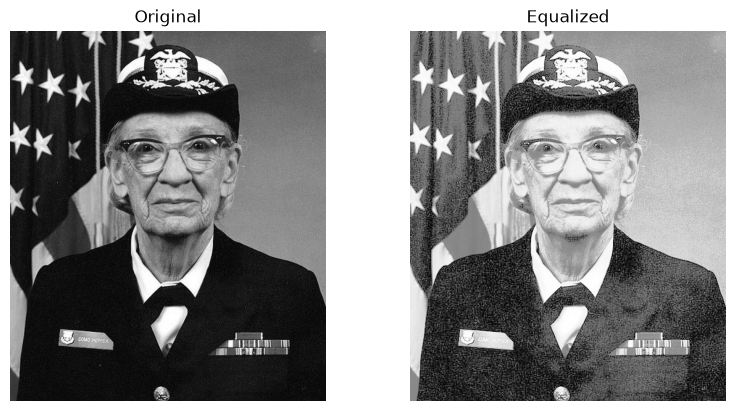

In [23]:
# Question 1
source_counts = cumulative_histogram(image)
first_count = source_counts[image.min()]
if first_count == image.size:
    equalized = image.copy()
else:
    scaled = (source_counts - first_count) * (255 / (image.size - first_count))
    equalization_map = np.rint(np.clip(scaled, 0, 255)).astype(np.uint8)
    equalized = equalization_map[image]

fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
for ax, result, title in zip(axes, (image, equalized), ("Original", "Equalized")):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()

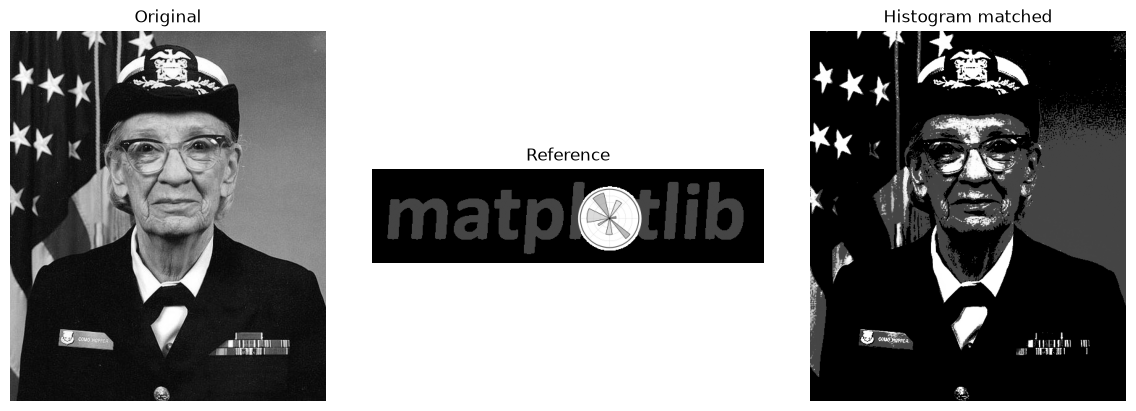

In [24]:
# Question 2
reference_path = get_sample_data("logo2.png", asfileobj=False)
with Image.open(reference_path) as source:
    reference = np.asarray(source.convert("L"))

reference_levels = np.unique(reference)
source_counts_scaled = cumulative_histogram(image) * reference.size
reference_counts_scaled = cumulative_histogram(reference)[reference_levels] * image.size

cdf_distances = np.abs(source_counts_scaled[:, None] - reference_counts_scaled)
matching_map = reference_levels[cdf_distances.argmin(axis=1)]
matched = matching_map[image]

fig, axes = plt.subplots(1, 3, figsize=(12, 4), layout="constrained")
for ax, result, title in zip(
    axes, (image, reference, matched), ("Original", "Reference", "Histogram matched")
):
    ax.imshow(result, cmap="gray", vmin=0, vmax=255)
    ax.set_title(title)
    ax.axis("off")
plt.show()